# 04 · Uncertainty calibration with TISSUE

Can we trust imputation for genes we have *not* measured? TISSUE turns LOO predictions into calibrated prediction intervals (PIs):

1. **Spatial graph**: k-NN (k = 15) pruned at Q3 + 1.5·IQR of edge lengths
2. **Cell-centred variability (CCV)**: how much a cell's prediction differs from its neighbours
3. **Conformal scores** `|observed − predicted| / CCV`, stratified by 2-level k-means groups (4 gene groups x 2 cell groups)
4. **Prediction intervals** at `alpha = 0.23` (77% intervals)

If the uncertainty is useful, cells with larger error should get wider intervals: per gene, Spearman ρ(|error|, PI width) should be clearly > 0.

Needs TISSUE (`impute` extras) and `results/gene_metrics.csv` from notebook 03.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st

from spatial_imputation import config, data, metrics, stats, plotting
plotting.set_style()

In [2]:
from spatial_imputation import uncertainty

DATASET = "d2"
adata, reference = data.load_analysis_inputs(DATASET)
gene_props = (pd.read_csv(config.RESULTS_DIR / "gene_metrics.csv")
              .query("dataset == @DATASET.upper() and method == 'Tangram'")
              .set_index("gene")[["moran_i", "sparsity_sp"]])
adata

AnnData object with n_obs × n_vars = 51377 × 296
    obs: 'volume', 'center_x', 'center_y', 'n_counts', 'n_genes', 'leiden', 'uniform_density', 'rna_count_based_density'
    var: 'mean', 'std', 'sparsity', 'n_cells'
    uns: 'log1p', 'overlap_genes', 'training_genes'
    obsm: 'tangram_predictions', 'spage_predictions', 'spatial'

## Calibrate both methods

In [3]:
for m in config.METHODS:
    uncertainty.calibrate(adata, f"{m}_predictions", alpha_level=0.23)

/Users/Amith/miniforge3/envs/abc_atlas/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO     Creating graph using `None` transform and `1` libraries.                                                  


/Users/Amith/miniforge3/envs/abc_atlas/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/Users/Amith/miniforge3/envs/abc_atlas/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/private/tmp/claude-502/-Users-Amith-Documents-Documents---Viji-s-MacBook-Pro-Work-LIDo-PhD--Rotation-Year-Rotation-2-Project-Work/0dc8d79d-8ae8-4d16-9e79-73913bcfb190/scratchpad/venv/lib/python3.11/site-packages/tissue/main.py:221: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, n_neighs=n_neighbors, coord_type="generic", set_diag=set_diag)


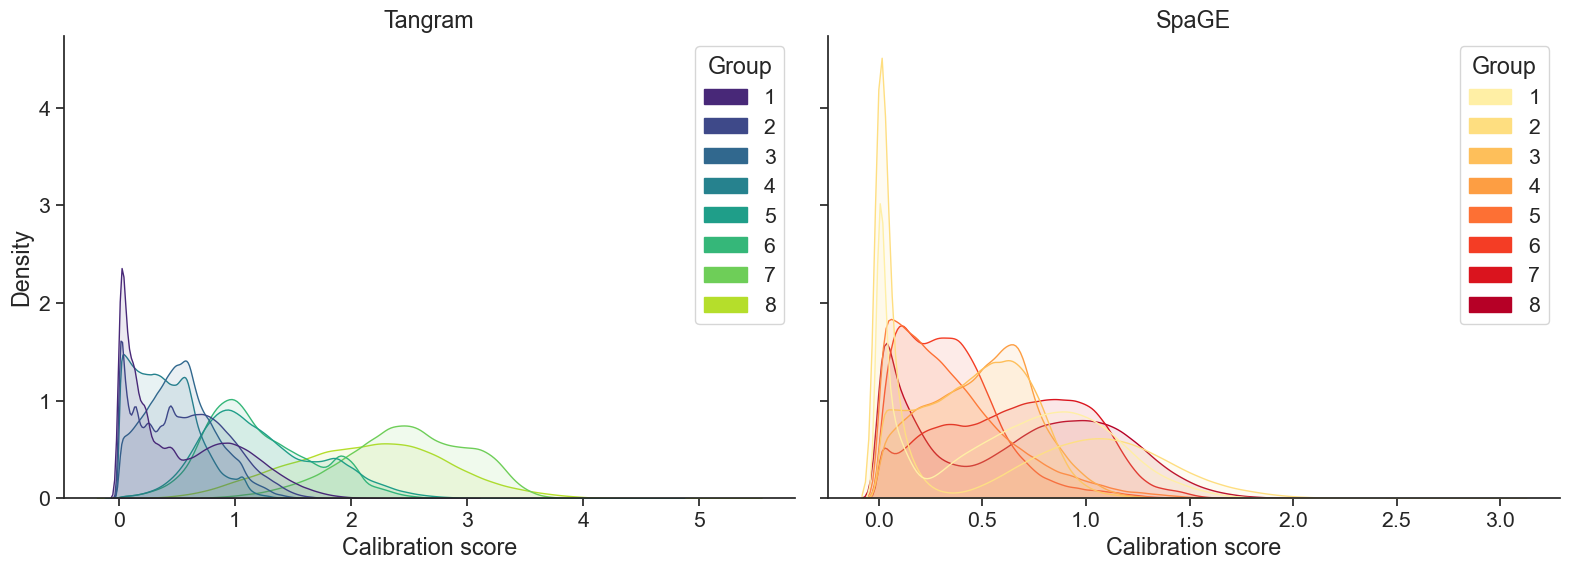

In [4]:
plotting.plot_calibration_kde({config.METHOD_LABELS[m]: uncertainty.calibration_scores(adata, f"{m}_predictions")
                               for m in config.METHODS});

## Does uncertainty track error?

,mean,median,std
method,,,
SpaGE,0.130,0.109,0.153
Tangram,0.123,0.120,0.132


ccv: Wilcoxon Tangram vs SpaGE  W = 20676, p = 3.77e-01


,mean,median,std
method,,,
SpaGE,0.064,0.058,0.168
Tangram,0.108,0.110,0.214


pi_width: Wilcoxon Tangram vs SpaGE  W = 17085, p = 9.00e-04


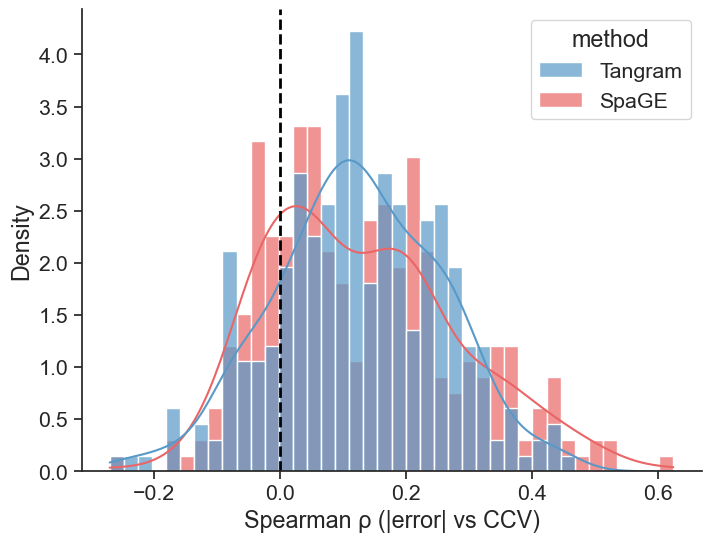

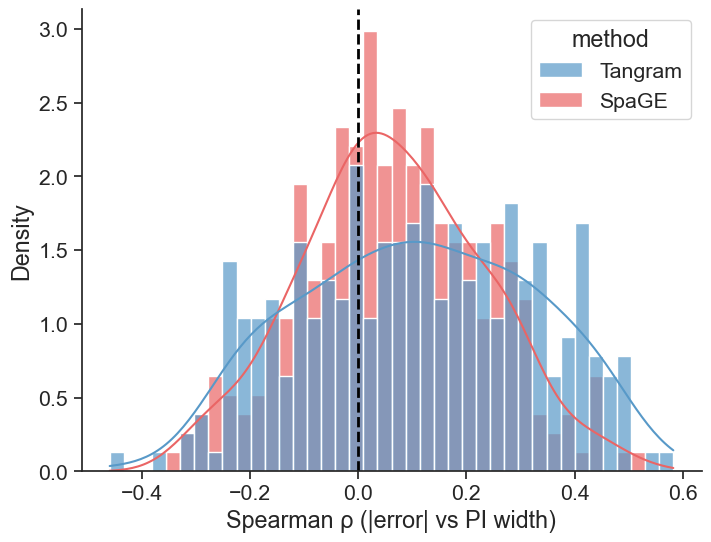

In [5]:
rel = {}
for kind, label in [("ccv", "Spearman ρ (|error| vs CCV)"), ("pi_width", "Spearman ρ (|error| vs PI width)")]:
    rel[kind] = {config.METHOD_LABELS[m]: uncertainty.error_vs_uncertainty(adata, f"{m}_predictions", kind)
                 for m in config.METHODS}
    long = pd.concat([s.rename("rho").to_frame().assign(method=k) for k, s in rel[kind].items()])
    display(long.groupby("method")["rho"].agg(["mean", "median", "std"]).round(3))
    both = pd.concat({k: s for k, s in rel[kind].items()}, axis=1).dropna()
    w = st.wilcoxon(both["Tangram"], both["SpaGE"])
    print(f"{kind}: Wilcoxon Tangram vs SpaGE  W = {w.statistic:.0f}, p = {w.pvalue:.2e}")
    plotting.plot_reliability_hist(long, label)

### Which genes get reliable intervals?
Genes split into quartiles of ρ(|error|, PI width); trend across quartiles (Spearman) and Q1 vs Q4 (Mann-Whitney).

Tangram


,property,trend_rho,trend_p,q1_vs_q4_p
0,moran_i,0.0410,0.4824,0.3978
1,sparsity_sp,-0.5074,0.0000,0.0000


SpaGE


,property,trend_rho,trend_p,q1_vs_q4_p
0,moran_i,0.235,0.0,0.0
1,sparsity_sp,-0.392,0.0,0.0


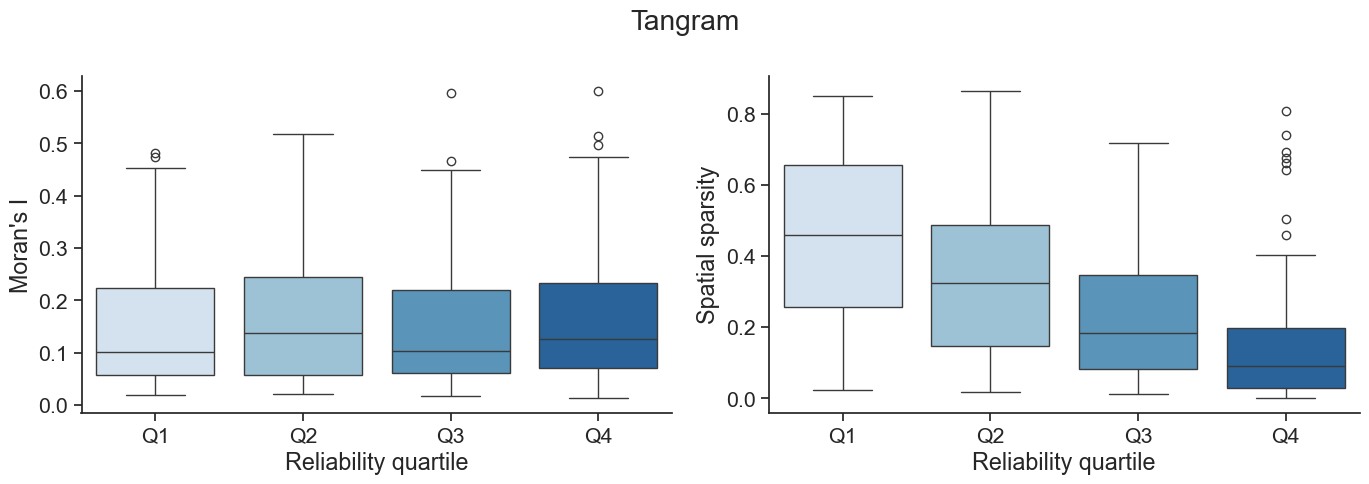

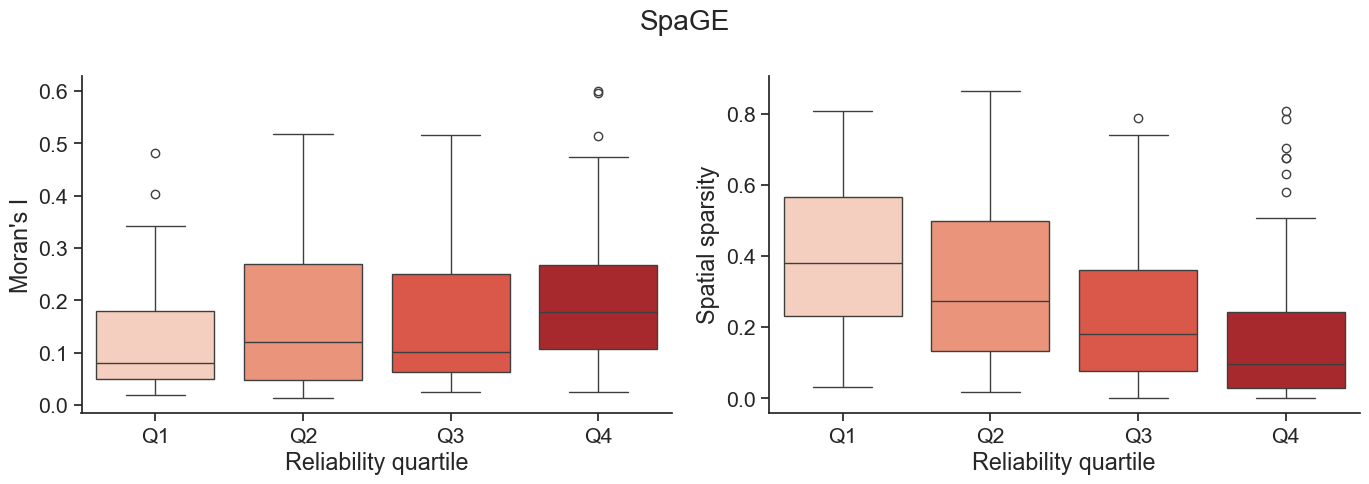

In [6]:
for method, r in rel["pi_width"].items():
    q, tests = uncertainty.reliability_quartiles(r, gene_props)
    print(method); display(tests.round(4))
    plotting.plot_quartile_boxes(q, method)

### Case study: most and least reliable SpaGE genes (zoomed)

plp1       0.521
tmem59l   -0.332
Name: rho_error_pi_width, dtype: float64


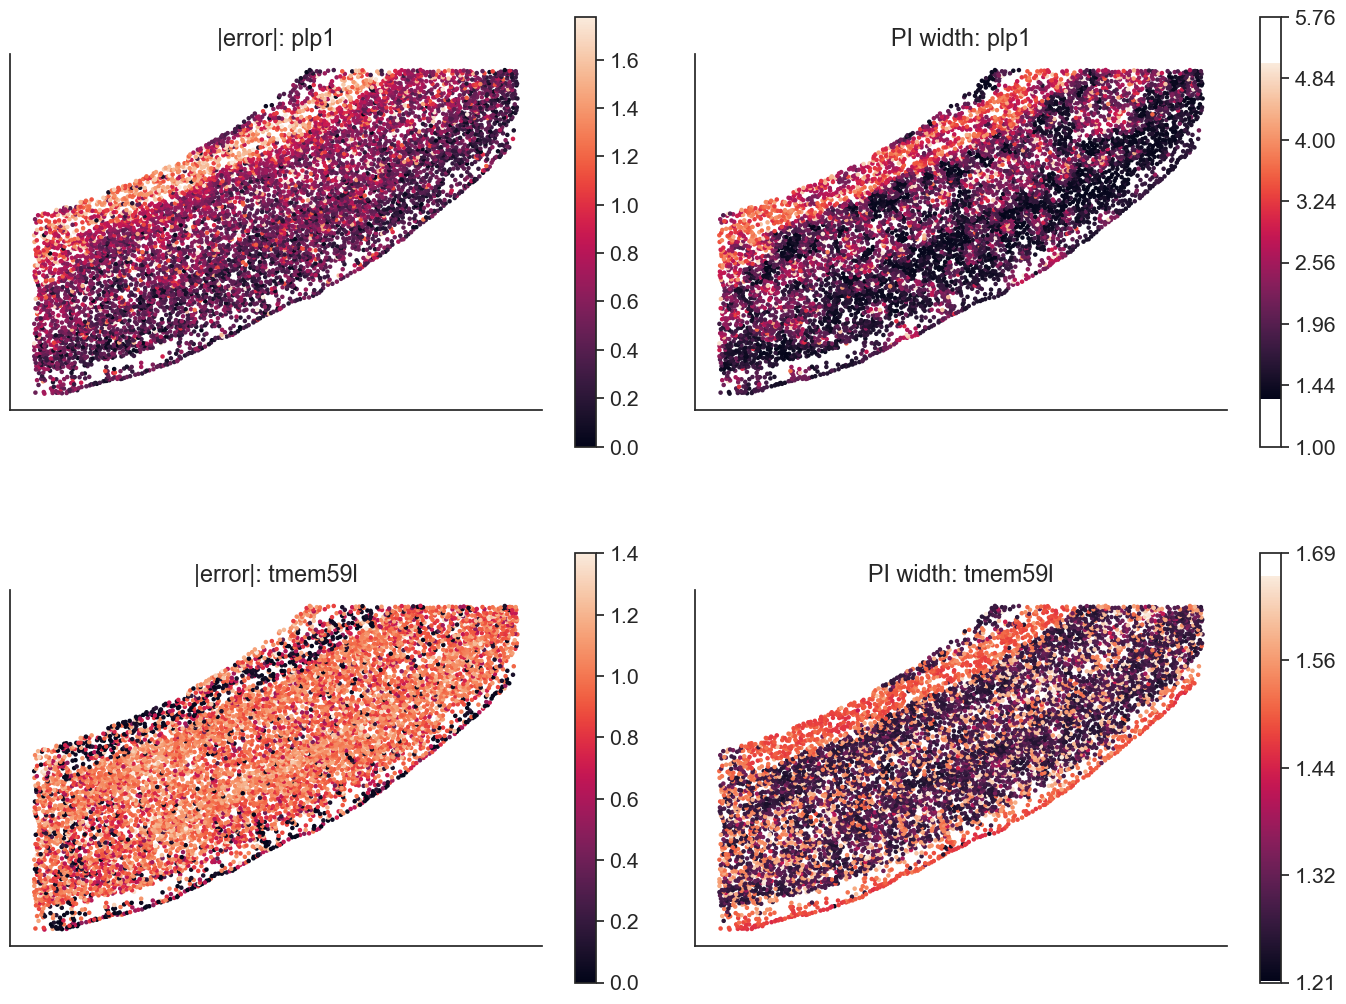

In [7]:
r = rel["pi_width"]["SpaGE"].sort_values()
genes = [r.index[-1], r.index[0]]
print(r.loc[genes].round(3))
plotting.plot_error_and_pi(adata, "spage_predictions", genes, xlim=(6000, 8500), ylim=(325, 2000));

## Summary (D2)

- **TISSUE's uncertainty is a weak guide to real error here.** Per gene, Spearman ρ(|error|, PI width) averages 0.06 for SpaGE and 0.11 for Tangram (Tangram higher, Wilcoxon p = 9e-4). Cell-centred variability is no better (ρ ≈ 0.12-0.13 for both).
- **Intervals are more informative for less sparse genes** (quartile trend ρ = -0.51 Tangram, -0.39 SpaGE). Spatial structure helps only for SpaGE (ρ = 0.24).
- **Implication:** imputation reproduces known spatial patterns, but its uncertainty estimates are not reliable enough to support confident claims about unmeasured genes in this data.